# Figure 5 panels B, C, D and G

Data is read from `data/summary/`.

| Panel | Shows | Source |
|---|---|---|
| B | contact-weighted ipTM across restraint cutoffs | `chai1r_summary_seeds1to8.csv` |
| C | DockQ of the ipTM-selected model, same pairing | `chai1r_summary_seeds1to8.csv` |
| D | ipTM against DockQ, 112 individual runs | `chai1r_summary_seeds1to8.csv` |
| G | CDR-loop C&alpha; RMSD | `cdr_rmsd.csv` |

In [1]:
import sys, pathlib
sys.path.insert(0, ".")
from figstyle import AB_COLOR, AB_MARKER, fs, plt, W_PANEL, H_PANEL

import numpy as np
import pandas as pd
from scipy.stats import ttest_rel

sys.path.insert(0, "..")
from ekochai import config as C

SUMMARY = pathlib.Path("../data/summary")
pred = pd.read_csv(SUMMARY / "chai1r_summary_seeds1to8.csv")

COND_ORDER = ["no_restraints"] + [f"restraints_{c}" for c in C.RESTRAINT_CUTOFFS]
COND_LABEL = ["none"] + [str(c) for c in C.RESTRAINT_CUTOFFS]
ANTIBODIES = C.ANTIBODIES

assert set(pred.condition_label) == set(COND_ORDER)
print(f"{len(pred)} rows = {pred.antibody.nunique()} antibodies"
      f" x {pred.seed.nunique()} seeds x {pred.condition_label.nunique()} conditions")

336 rows = 7 antibodies x 8 seeds x 6 conditions


## Panels B and C

In [2]:
def best_over_seeds(df, metric="wipTM_Ab_ag", dockq="DockQ_best_wiPTM"):
    b = df.loc[df.groupby(["antibody", "condition_label"])[metric].idxmax()]
    wide = [b.pivot(index="antibody", columns="condition_label", values=v)
             .reindex(index=ANTIBODIES, columns=COND_ORDER) for v in (metric, dockq)]
    assert all(w.notna().all().all() for w in wide)
    return wide

w_iptm, w_dockq = best_over_seeds(pred)
display(w_iptm.round(3), w_dockq.round(3))

condition_label,no_restraints,restraints_8,restraints_12,restraints_16,restraints_20,restraints_24
antibody,,,,,,
HEPC108,0.307,0.459,0.409,0.433,0.539,0.322
hcab55,0.284,0.427,0.380,0.415,0.348,0.295
hcab64,0.210,0.527,0.483,0.504,0.454,0.223
hcab17,0.196,0.327,0.340,0.320,0.375,0.205
hcab44,0.322,0.721,0.717,0.717,0.724,0.337
hcab23,0.208,0.645,0.649,0.650,0.304,0.209
hcab40,0.266,0.497,0.450,0.333,0.252,0.273


condition_label,no_restraints,restraints_8,restraints_12,restraints_16,restraints_20,restraints_24
antibody,,,,,,
HEPC108,0.156,0.046,0.343,0.462,0.254,0.130
hcab55,0.046,0.187,0.186,0.244,0.245,0.051
hcab64,0.030,0.197,0.259,0.249,0.283,0.030
hcab17,0.010,0.042,0.163,0.152,0.018,0.010
hcab44,0.036,0.356,0.543,0.283,0.511,0.026
hcab23,0.032,0.529,0.553,0.509,0.039,0.028
hcab40,0.030,0.022,0.029,0.031,0.038,0.028


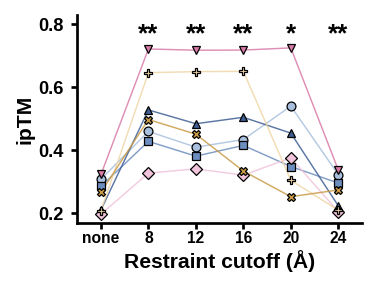

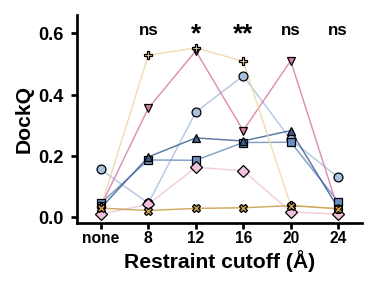

In [3]:
def stars(p):
    return "***" if p < 1e-3 else "**" if p < 1e-2 else "*" if p < 0.05 else "ns"


def paired_panel(wide, ylabel):
    fig, ax = plt.subplots(figsize=(W_PANEL, H_PANEL))
    x = np.arange(len(COND_ORDER))
    for ab in ANTIBODIES:
        y = wide.loc[ab].values
        ax.plot(x, y, "-", lw=0.7, color=AB_COLOR[ab], alpha=0.85, zorder=2)
        ax.plot(x, y, ls="none", marker=AB_MARKER[ab], ms=4.25,
                mfc=AB_COLOR[ab], mec="black", mew=0.6, zorder=3)

    base = wide["no_restraints"].values
    top, rng = np.nanmax(wide.values), np.ptp(wide.values)
    for k, c in enumerate(COND_ORDER[1:], start=1):
        lab = stars(ttest_rel(wide[c].values, base).pvalue)
        # "*" occupies only the top of its em box while "ns" is full x-height,
        # so at one point size "ns" reads far larger. Size them separately.
        dy, size = (0.06, 6.5) if lab == "ns" else (0.01, 10.0)
        ax.text(k, top + dy * rng, lab, ha="center", va="bottom",
                fontsize=fs(size), fontweight="bold")
    ax.set_ylim(top=top + 0.20 * rng)
    ax.set_xticks(x); ax.set_xticklabels(COND_LABEL, fontsize=fs(6.0))
    ax.tick_params(axis="x", pad=1)
    ax.set_xlim(-0.5, len(x) - 0.5)
    ax.set_xlabel("Restraint cutoff (Å)", labelpad=2, fontsize=fs(8.1))
    ax.set_ylabel(ylabel, labelpad=2, fontsize=fs(8.1))
    return fig


paired_panel(w_iptm, "ipTM")
paired_panel(w_dockq, "DockQ")
plt.show()

In [4]:
# the numbers behind the two panels
stats = pd.DataFrame([
    dict(condition=c,
         iPTM_delta=round(w_iptm[c].mean() - w_iptm["no_restraints"].mean(), 4),
         iPTM_p=round(ttest_rel(w_iptm[c].values,
                                w_iptm["no_restraints"].values).pvalue, 4),
         DockQ_delta=round(w_dockq[c].mean() - w_dockq["no_restraints"].mean(), 4),
         DockQ_p=round(ttest_rel(w_dockq[c].values,
                                 w_dockq["no_restraints"].values).pvalue, 4))
    for c in COND_ORDER[1:]])
display(stats)
print("ipTM peaks at", w_iptm.mean().idxmax(),
      "| DockQ peaks at", w_dockq.mean().idxmax(),
      "- the score's optimum is not the accuracy optimum")

,condition,iPTM_delta,iPTM_p,DockQ_delta,DockQ_p
0,restraints_8,0.2584,0.0017,0.1484,0.1061
1,restraints_12,0.2335,0.0045,0.2480,0.0152
2,restraints_16,0.2254,0.0073,0.2271,0.0063
3,restraints_20,0.1717,0.0164,0.1497,0.0634
4,restraints_24,0.0100,0.0016,-0.0053,0.2198


ipTM peaks at restraints_8 | DockQ peaks at restraints_12 - the score's optimum is not the accuracy optimum


## Panel D

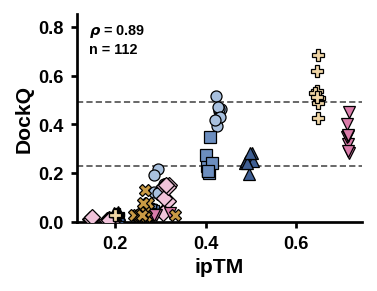

n = 112   Spearman rho = 0.892   Pearson r = 0.851


In [5]:
sc = pred[pred.condition_label.isin(["no_restraints", "restraints_16"])][
         ["antibody", "wipTM_Ab_ag", "DockQ_best_wiPTM"]].dropna()

fig, ax = plt.subplots(figsize=(W_PANEL, H_PANEL))
for ab in ANTIBODIES:
    s = sc[sc.antibody == ab]
    ax.plot(s.wipTM_Ab_ag, s.DockQ_best_wiPTM, ls="none", marker=AB_MARKER[ab],
            ms=5.3, mfc=AB_COLOR[ab], mec="black", mew=0.6, zorder=3)
for cut in (C.DOCKQ_ACCEPTABLE, C.DOCKQ_MEDIUM):
    ax.axhline(cut, color="0.35", lw=0.85, ls=(0, (3.5, 1.8)), zorder=2)

rho = sc.wipTM_Ab_ag.rank().corr(sc.DockQ_best_wiPTM.rank())
ax.text(0.04, 0.96, f"$\\rho$ = {rho:.2f}\nn = {len(sc)}", transform=ax.transAxes,
        va="top", ha="left", fontsize=fs(5.5), fontweight="bold")
ax.set_xlabel("ipTM", labelpad=2, fontsize=fs(8.1))
ax.set_ylabel("DockQ", labelpad=2, fontsize=fs(8.1))
ax.set_ylim(0, 0.85)
plt.show()

print(f"n = {len(sc)}   Spearman rho = {rho:.3f}   "
      f"Pearson r = {sc.wipTM_Ab_ag.corr(sc.DockQ_best_wiPTM):.3f}")

## Panel G &mdash; CDR-loop C&alpha; RMSD

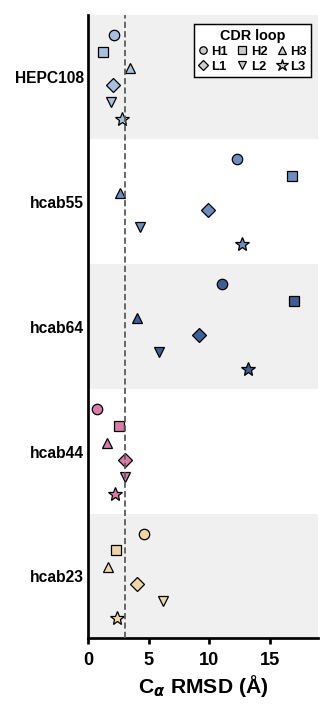

antibody,HEPC108,hcab55,hcab64,hcab44,hcab23
cdr,,,,,
H1,2.14,12.30,11.06,0.75,4.58
H2,1.21,16.84,16.96,2.55,2.28
H3,3.43,2.58,4.01,1.58,1.61
L1,2.03,9.92,9.17,3.03,4.06
L2,1.89,4.26,5.87,3.00,6.20
L3,2.80,12.71,13.16,2.21,2.33


,"mean RMSD, E2 frame","mean RMSD, Fv frame"
antibody,,
HEPC108,2.25,1.90
hcab55,9.77,2.17
hcab64,10.04,1.44
hcab44,2.19,0.84
hcab23,3.51,1.86


In [6]:
cdr_df = pd.read_csv(SUMMARY / "cdr_rmsd.csv")
G_ANTIBODIES = ["HEPC108", "hcab55", "hcab64", "hcab44", "hcab23"]
CDRS = ["H1", "H2", "H3", "L1", "L2", "L3"]
CDR_MARKER = {"H1": "o", "H2": "s", "H3": "^", "L1": "D", "L2": "v", "L3": "*"}
CDR_MS = {"*": 7.2}
W_G, H_G = 1.98, 5.40            # taller than the other panels: 5 rows
RMSD_REF = 3.0

assert not {(a, c) for a in G_ANTIBODIES for c in CDRS} - set(zip(cdr_df.antibody,
                                                                 cdr_df.cdr))

fig, ax = plt.subplots(figsize=(W_G, H_G))
ax.axvline(RMSD_REF, color="0.35", lw=0.85, ls=(0, (3.5, 1.8)), zorder=4)
offs = np.linspace(-0.34, 0.34, len(CDRS))
for yi, ab in enumerate(G_ANTIBODIES):
    if yi % 2 == 0:
        ax.axhspan(yi - 0.5, yi + 0.5, color="0.94", lw=0, zorder=0)
    for off, c in zip(offs, CDRS):
        v = cdr_df[(cdr_df.antibody == ab) & (cdr_df.cdr == c)].rmsd.iloc[0]
        m = CDR_MARKER[c]
        ax.plot(v, yi + off, marker=m, ms=CDR_MS.get(m, 5.0), mfc=AB_COLOR[ab],
                mec="black", mew=0.6, ls="none", zorder=3)

# matplotlib fills legend columns top-to-bottom, so interleave to get
# H1 H2 H3 on the first row and L1 L2 L3 on the second
handles = [plt.Line2D([], [], ls="none", marker=CDR_MARKER[c],
                      ms=CDR_MS.get(CDR_MARKER[c], 4.2) * 0.85,
                      mfc="0.80", mec="black", mew=0.6, label=c)
           for c in ["H1", "L1", "H2", "L2", "H3", "L3"]]
leg = ax.legend(handles=handles, ncol=3, title="CDR loop", fontsize=fs(5.0),
                title_fontsize=fs(5.5), handlelength=0.8, handletextpad=0.25,
                columnspacing=0.7, labelspacing=0.25, borderpad=0.3,
                loc="upper right", bbox_to_anchor=(0.995, 0.995),
                frameon=True, fancybox=False, framealpha=1.0)
leg.get_title().set_fontweight("bold")
leg.get_frame().set_edgecolor("black"); leg.get_frame().set_linewidth(0.7)

ax.set_yticks(range(len(G_ANTIBODIES)))
ax.set_yticklabels(G_ANTIBODIES, fontsize=fs(6.0))
ax.set_ylim(len(G_ANTIBODIES) - 0.5, -0.5)
ax.tick_params(axis="y", pad=2, length=0)
ax.set_xlim(0, max(4.0, cdr_df.rmsd.max() * 1.12))
ax.set_xlabel("C$_\\alpha$ RMSD (Å)", labelpad=2, fontsize=fs(8.1))
plt.show()

display(cdr_df.pivot(index="cdr", columns="antibody", values="rmsd")
        .reindex(index=CDRS, columns=G_ANTIBODIES).round(2),
        cdr_df[cdr_df.antibody.isin(G_ANTIBODIES)]
        .groupby("antibody")[["rmsd", "rmsd_framework"]].mean()
        .reindex(G_ANTIBODIES).round(2)
        .rename(columns={"rmsd": "mean RMSD, E2 frame",
                         "rmsd_framework": "mean RMSD, Fv frame"}))